**Проект Модель для сбора статистики в МФЦ**

In [10]:
import pandas as pd
import numpy as np
from urllib3.contrib.emscripten.fetch import is_cross_origin_isolated

Нам дан датасет с картинками FER-2013, взятый с платформы Kaggle. Архив содержит две папки: train и test.  Для того чтобы работать дальше с данными необходимо загрузить данные в компьютер. Используем модули datasets и transforms из библиотеки torchvision для обработки картинок по следующим пунктам:
1. Чтение файлов
2. Приведение картинок к одной размерности
3. Нормализация
Опираясь на эту статью https://learn.microsoft.com/ru-ru/windows/ai/windows-ml/tutorials/pytorch-data напишем код, дополнительно задав размер (48 * 48) как в оригинальном датасете и для тренировочных данных сделаем дополнительное отзеркаливание, чтобы разнообразить данные. затем с помощью ImageFolder загрузим данные.
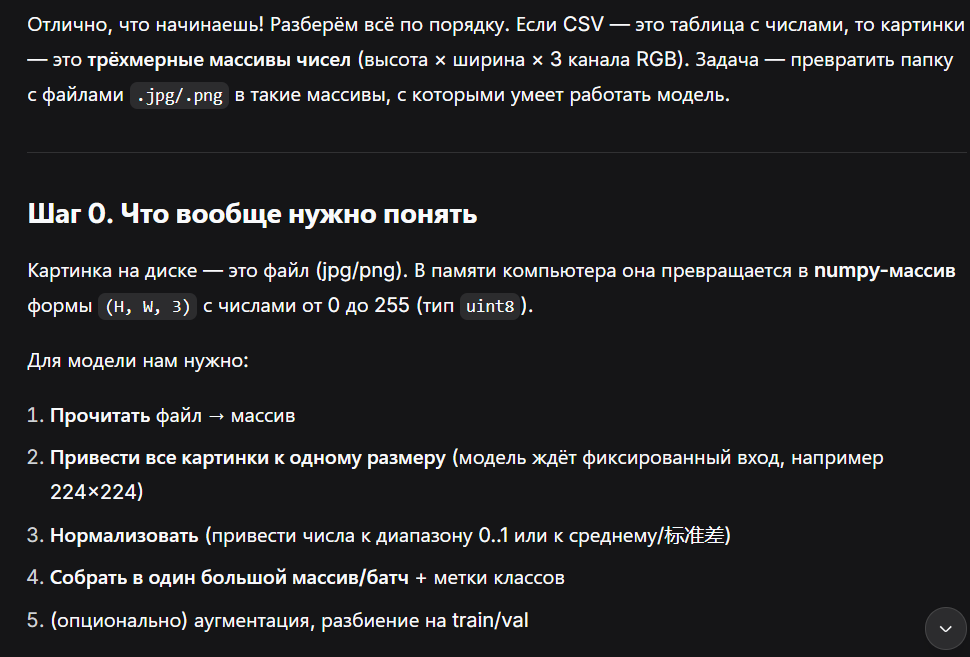

In [12]:
from torchvision import datasets, transforms
transforms_train = transforms.Compose([
    transforms.Grayscale(1),
    #задаем размер
    transforms.Resize((48, 48)),
    #отзеркаливание
    transforms.RandomHorizontalFlip(),
    #тензор
    transforms.ToTensor()
])
transforms_test = transforms.Compose([
    transforms.Grayscale(1),
    transforms.Resize((48, 48)),
    transforms.ToTensor()
])

через ImageFolder загрузим данные (синтаксис: https://docs.pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html)
По сути в начале мы получаем массив в формате:


train/happy/im1.png, 0



train/anry/im2.png, 1
...


где число - номер класса. + мы храним дополнительную информацию о том как именно нужно преобразовывать изображение (transform).

In [13]:
#датасеты для обучения (описание + как обработать)
train_df = datasets.ImageFolder(root='train', transform=transforms_train)
test_df = datasets.ImageFolder(root='test', transform=transforms_test)

#разбиение по батчам + реальные картинки
from torch.utils.data import DataLoader
train = DataLoader(train_df, batch_size=64, shuffle=True, num_workers=0)
test = DataLoader(test_df, batch_size=64, shuffle=False)

Вместо EDA лучше сразу проверим на kaggle в разделе описания датасета сколько картинок в каждом классе и увидим, что есть дисбаланс (happy - 1774, disgust - 111). для этого перед тем как обучить модель стоит навесить штраф на популярный класс.

Напишем архитектуру сверточной нейронной сети (CNN), так как для работы с изображениями лучше всего подходит именно она. обычные линейные модели или CatBoost выдавали бы низкие результаты, нам же важна точность.

Теория:
сверточная нейронная сеть - состоит из слоев, каждый из которых включает в себя:


1. Слой свертки (окошко, которое двигается по всей картинке)
2. ReLU (слой нелинейности, функция активации)
3. MaxPool (выделяет значимые признаки + уменьшает пространственные размеры)


Помимо этого есть еще слой Flatten - преобразует изображение в непрерывный массив, линейный слой - делает преобразование/смещение за счет весов и линейных операций.

In [14]:
import torch.nn as nn
import torch
import torch.nn.functional as F
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        #1. 48*48
        #(кол-во входных каналов, кол-во каналов на выходе, размер ядра свертки, кол-во доп нулей по краям изображения
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        #уменьшение изображения по длине и ширине в 2 раза
        self.maxpool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        #2. 24*24
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.maxpool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        #3. 12*12
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        #4 12*12
        self.conv4 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)

        self.flatten = nn.Flatten()

        #каналы * высота * ширина, кол-во нейронов (преобразование в вектор)
        self.f1 = nn.Linear(128 * 12 * 12, 256)

        #случайное отключение 30% нейронов для того чтобы модель не переобучилась
        self.dropout = nn.Dropout(0.3)
        #кол-во нейронов, кол-во классов
        self.f2 = nn.Linear(256, num_classes)

    def forward(self, x):
        #добавим слой нелинейности ReLU
        x = F.relu(self.conv1(x))
        x = self.maxpool1(x)
        x = F.relu(self.conv2(x))
        x = self.maxpool2(x)
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.flatten(x)
        x = F.relu(self.f1(x))
        x = self.dropout(x)
        x = self.f2(x)
        return x

Теперь обучим модель на тренировочных данных и сделаем предсказание на тестовых данных.
Для этого объявим модель, выберем по какой метрике будем считать ошибку, я возьму стандартную кросс-энтропию, и возьмем стандартный оптимизатор для того чтобы он решал как именно изменять параметры после подсчета градиента. шаг обучения возьмем маленький (1e-3).

In [15]:
import torch
import torch.optim as optim
#выбор устройства вычислений
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#кол-во классов
num_classes = len(train_df.classes)
#объявляем модель
model = CNN(num_classes=num_classes)
#функция потерь
criterion = nn.CrossEntropyLoss()
#оптимизатор адам
optimizer = optim.Adam(model.parameters(), lr=1e-3)
#кол-во эпох возьмем вместо 30 - 15 так как при бОльшем кол-ве эпох модель переобучается
cnt_epoch= 15
#для того, чтобы построить график будем складывать ошибки по эпохам
loss_list = []
for epoch in range(cnt_epoch):
    #объявляем модель (включаются функции для обучения например dropout)
    model.train()
    #кол-во правильных ответов модели и общее кол-во ответов
    cnt_true = 0
    cnt = 0
    cnt_loss = 0
    sum_loss = 0
    #проход по картинкам (батчам) и их правильным классам
    for x_batch, y_batch in train:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        #обнуление градиентов (так как они накапливаются для каждого батча -> для нового нужно начинать с нуля)
        optimizer.zero_grad()
        #делаем предсказание (возвращает список логитов, которые берутся из последнего линейного слоя и домножаются на веса, взвешенная сумма)
        y_pred = model(x_batch)
        #передаем в лосс полученое предсказание и правильный ответ, считаем ошибку
        #кросс-энтропия сама делает softmax (преобразует логиты в вероятности) поэтому выше мы не прописывали sofmax
        loss = criterion(y_pred, y_batch)
        #считаем как каждый параметр повлиял на ошибку (считаем градиенты)
        loss.backward()
        #изменяем веса опираясь на полученные результаты (на градиенты), делаем шаг оптимизации
        optimizer.step()
        #ищем самый большой логит в списке
        pred = torch.argmax(y_pred, dim=1)
        cnt += len(y_batch)
        #считаем кол-во правильных ответов
        cnt_true += (pred == y_batch).sum().item()
        #для подсчета средней ошибки
        sum_loss += loss.item()
        cnt_loss += 1
    #среднее значение по батчу
    loss_mean = sum_loss / cnt_loss
    #добавляем в массив
    loss_list.append(loss_mean)
    #доля верных ответов
    accuracy = cnt_true / cnt
    print(f'epoch: {epoch}, loss: {loss_mean}, Доля верных ответов: {accuracy}')
print('Finished Training!🥹😍')


epoch: 0, loss: 1.6797449493195804, Доля верных ответов: 0.3296875544254415
epoch: 1, loss: 1.4727701705388874, Доля верных ответов: 0.430318018739768
epoch: 2, loss: 1.3558059086512881, Доля верных ответов: 0.48322825594761226
epoch: 3, loss: 1.274887484006733, Доля верных ответов: 0.5164582535093525
epoch: 4, loss: 1.211254681802805, Доля верных ответов: 0.5405970253230694
epoch: 5, loss: 1.1601981256480738, Доля верных ответов: 0.5620885436622662
epoch: 6, loss: 1.1055928054524955, Доля верных ответов: 0.5852520115643178
epoch: 7, loss: 1.0525955657385506, Доля верных ответов: 0.6023546623010206
epoch: 8, loss: 0.9984322084084917, Доля верных ответов: 0.6246473231390853
epoch: 9, loss: 0.9504835391894215, Доля верных ответов: 0.6430039360479293
epoch: 10, loss: 0.891016705264493, Доля верных ответов: 0.6663415653627782
epoch: 11, loss: 0.8426353480077798, Доля верных ответов: 0.6853251593576927
epoch: 12, loss: 0.7824071044380256, Доля верных ответов: 0.7080009753039117
epoch: 13, l

Подбор кол-ва эпох показал, что после 20 эпохи происходит переобучение модели (loss перестал падать, а правильные ответы растут). снизим число эпох до 17 и посмотрим что будет.
Все-таки стоит попробовать сделать кросс-валидацию чтобы оценить качество обученой модели.


Построим график изменения уровня ошибки на протяжении 10 эпох обучения

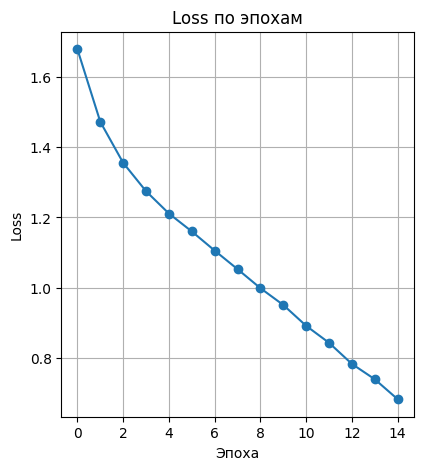

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(loss_list, marker='o')
plt.title('Loss по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

Сохраним модель с ее весами

In [17]:
torch.save(model.state_dict(), 'CNN.pth')

In [19]:
#отключаем dropout
model.eval()
with torch.no_grad():
    cnt_true = 0
    cnt = 0
    for x_batch, y_batch in test:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        y_pred = model(x_batch)
        loss = criterion(y_pred, y_batch)
        pred = torch.argmax(y_pred, dim=1)
        cnt += len(y_batch)
        cnt_true += (pred == y_batch).sum().item()
    print(f'Результат на тестовой выборке: {cnt_true / cnt}')

Результат на тестовой выборке: 0.5697966007244358


In [34]:
import cv2 as cv
import time
emotion = ''
#создаем двумерный массив с вероятностями для каждого класса
cl_v = [[] for _ in range(7)]
classes = ['angry', 'disgust', 'fear', 'happy','neutral', 'sad', 'surprise']
ang = []
disg = []
fear = []
happy = []
neutral = []
sad = []
surprise = []
def dispercia(arr):
    cr = sum(arr) / len(arr)
    summa = 0
    cnt = 0
    for i in range(len(arr)):
        summa += (cr - arr[i]) ** 2
        cnt += 1
    return cr, summa / cnt
capture = cv.VideoCapture(0)
for i in range(30):
    #тру и кадр равны захвату, считываем логическое(вывел ли видео) значение и кадр
    ret, frame = capture.read()
    tensor = transforms.Compose([
        #так как opencv дает кадр в numpy преобразуем его в PIL
        transforms.ToPILImage(),
        #чб
        transforms.Grayscale(1),
        #размер
        transforms.Resize((48, 48)),
        #тензор
        transforms.ToTensor()
    ])
    img = tensor(frame)
    #преобразуем в батч
    batch_img = img.unsqueeze(0)
    with torch.no_grad():
        batch_img = batch_img.to(device)
        #мы получиои массив с логитами для каждого класса, преобразуем эти числа в вероятность каждого класса и составим двумерный массив, где каждый элемент - это класс, а подмассивы - вероятности для каждого класса по каждому изображению
        pred = model(batch_img)
        #преобразуем в вероятности
        pred = F.softmax(pred, dim=1)
        for c in range(7):
            cl_v[c].append(float(pred[0, c]))
        if i < 30:
            time.sleep(1)
capture.release()
#считаем среднее арифметическое и дисперсию для каждого класса, находим максимальное среднее и минимальное отклонение
i_cr = 0
mx = -10**10
mean = []
dis = []
for i in range(7):
    cr, d = dispercia(cl_v[i])
    mean.append(cr)
    dis.append(d)
    if cr > mx:
        mx = cr
        i_cr = i
#проверка что дисперсия и среднее не меньще чем 0,35 и 0,08, чтобы понять что эмоция распознана
if mean[i_cr] <= 0.35 or dis[i_cr] > 0.08:
    emotion = '-'
else:
    emotion = classes[i_cr]

fear
angry
happy
fear
happy
